In [1]:
import os
import pandas as pd
from importlib import reload
import numpy as np
import seaborn as sns
from tqdm import *
import scipy.special
from numpy.linalg import eigh
from joblib import Parallel, delayed
import matplotlib.pyplot as plt

In [2]:
def concat_model_4fold(test_path, res_path):
    market = 'ALL'
    model_res = []
    for valid_period in ['validperiod1', 'validperiod2', 'validperiod3', 'validperiod4']:
        data_path = rf"{test_path}/{market}-{valid_period}"
        date_list = list(set([x[:8] for x in os.listdir(data_path)]))
        date_list.sort()
        all_res = []
        for date in date_list:
            date_res = pd.read_pickle(f'{data_path}/{date}.pkl').T
            date_res.index = [date] * len(date_res)
            all_res.append(date_res)
        all_res = pd.concat(all_res, axis=0).sort_index()
        all_res.index.name = "date"
        model_res.append(all_res.apply(lambda x: (x - x.mean()) / x.std(), axis=1))
    model_res = sum(model_res)
    model_res.reset_index().to_feather(rf"{res_path}/{market}_zscore_score.fea")
    return model_res

# 根据模型打分获取对应的label_ret和ic
def get_ret_ic(score, ret_data, liquid_data, start='20230101', end='20241231', money=1.5e9, print_quarterly=False):
    model_score = score.copy()
    label_ret = []
    ic = []
    datelist = []
    # 这是一段日度调仓计算日度收益率的代码
    for date in model_score.loc[start:end].index:
        datelist.append(date)
        code_rank = model_score.loc[date].sort_values(ascending=False)
        ret = ret_data.loc[date].reindex(code_rank.index).fillna(0) * 100
        liquid = liquid_data.loc[date].reindex(code_rank.index).fillna(0)
        total_hold = 0
        total_earned = 0
        for num,code in enumerate(code_rank.index):
            if num >= 500:
                break
            if (money - total_hold) < 1:
                break
            hold_money = min(money - total_hold, liquid[code])
            total_hold += hold_money
            total_earned += ret[code] * hold_money
        total_ret = total_earned / money
        label_ret.append(total_ret)
        ic.append(code_rank.corr(ret))
    ic = pd.Series(ic, index=datelist, dtype='float')
    label_ret = pd.Series(label_ret, index=datelist, dtype='float')
    if print_quarterly:
        print_quarterly_metrics(label_ret, ic)
    return label_ret, ic

def print_quarterly_metrics(ret, ic):
    """打印每个季度的收益和IC指标"""
    ret_series = ret.copy()
    ic_series = ic.copy()
    ret_series.index = pd.to_datetime(ret_series.index)
    ic_series.index = pd.to_datetime(ic_series.index)
    quarterly_ret = ret_series.groupby(pd.Grouper(freq='QE')).mean()
    quarterly_ic = ic_series.groupby(pd.Grouper(freq='QE')).mean()
    quarterly_ret.index = [f"{idx.year}Q{idx.quarter}" for idx in quarterly_ret.index]
    quarterly_ic.index = [f"{idx.year}Q{idx.quarter}" for idx in quarterly_ic.index]
    quarterly_df = pd.DataFrame({
        '季度平均收益(%)': quarterly_ret.round(4),
        '季度平均IC': quarterly_ic.round(4)
    })
    print("\n===== 季度表现指标 =====")
    print(quarterly_df)
    print("=======================\n")

def get_metrics(score, ret_data, liquid_data, start='20230101', end='20241231', money=1.5e9, print_quarterly=True):
    ret_list, ic_list = get_ret_ic(score, ret_data, liquid_data, start=start, end=end, money=money, print_quarterly=print_quarterly)
    # 当前模型评价
    score_metrics = {
        "IC": ic_list.mean(),
        "ICIR": ic_list.mean() / ic_list.std() if ic_list.std() != 0 else 0,
        "top_return": ret_list.mean(),
        "top_return_stability": ret_list.mean() / ret_list.std() if ret_list.std() != 0 else 0
    }
    return score_metrics

def print_metrics(model_metrics, bench_metrics=None, title="模型评估结果"):
    metric_keys = list(model_metrics.keys())
    df = pd.DataFrame(index=metric_keys)
    df.index.name = "指标"
    df["模型值"] = [model_metrics[k] for k in metric_keys]
    if bench_metrics is not None:
        df["基准值"] = [bench_metrics.get(k, None) for k in metric_keys]
        df["提升值"] = ((df["模型值"] - df["基准值"]) / df["基准值"]) * 100
    print(f"\n{title}")
    print(df.round(4))

def plot_model(model_score, bench_score, ret_data, liquid_data, start='20230101', end='20241231', money=1.5e9):
    model_ret, _ = get_ret_ic(model_score, ret_data, liquid_data, start=start, end=end, money=money, print_quarterly=False)
    model_ret = model_ret/100
    bench_ret, _ = get_ret_ic(bench_score, ret_data, liquid_data, start=start, end=end, money=money, print_quarterly=False)
    bench_ret = bench_ret/100

    dates = model_ret.index.tolist()
    seen_months = set()
    month_ticks = []
    month_labels = []
    for i, d in enumerate(dates):
        month = d[:6] 
        if month not in seen_months:
            seen_months.add(month)
            month_ticks.append(i)
            month_labels.append(d)

    # 1. 绘制每日收益率曲线
    plt.figure(figsize=(12, 6))
    plt.plot(dates, model_ret.cumsum(), label='model', color='blue')
    plt.plot(dates, bench_ret.cumsum(), label='bench', color='orange')
    plt.title('Cumulative Return Of Model & Bench', fontsize=14)
    plt.ylabel('Cumulative Return(%)', fontsize=12)
    plt.xticks(ticks=month_ticks, labels=month_labels, rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()
    
    # 2. 绘制相对提升
    plt.figure(figsize=(12, 6))
    relative_improvement = model_ret - bench_ret
    plt.plot(dates, relative_improvement.cumsum(), label='model', color='blue')
    plt.title('Relative Iprovement', fontsize=14)
    plt.ylabel('Relative Iprovement(%)', fontsize=12)
    plt.xticks(ticks=month_ticks, labels=month_labels, rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()

def diversity_entropy(score):
    """
    计算 DE
    """
    if isinstance(score, pd.DataFrame):
        score = score.values
    m = score.shape[1]
    cov_matrix = np.cov(score, rowvar=False)
    eigenvalues, _ = eigh(cov_matrix)
    eigenvalues = np.sort(eigenvalues)[::-1]
    normalized_eigenvalues = eigenvalues / (np.sum(eigenvalues) + 1e-10)
    entropy = 0
    for p in normalized_eigenvalues:
        if p > 1e-10:  # 只对非零概率计算
            entropy -= p * np.log(p)
    de = entropy / np.log(m)
    return de

def ensemble_scores(*dfs):
    """
    输入：任意数量的打分 DataFrame（index=日期，columns=股票）
    输出：拼接后的 DataFrame，columns=score1, score2, ...
    """
    result_list = []
    for i, df in enumerate(dfs, 1):
        df_norm = df.copy()
        df_norm = df_norm.apply(lambda x: (x - x.mean()) / x.std(), axis=1)
        df_norm = df_norm.stack().rename(f"score{i}")
        result_list.append(df_norm)
    result = pd.concat(result_list, axis=1)
    return result.dropna()


# bench

In [3]:
# 标签
label_path = rf'/home/user96/label_data1'
label_name = rf'label1'
# 流动性数据
liquid_path = rf'/home/user96/label_data1'
liquid_name = rf'can_trade_amt1'
class params:
    liquid_data = pd.read_feather(rf"{liquid_path}/{liquid_name}.fea").set_index("index")
    ret_data = pd.read_feather(rf"{label_path}/{label_name}.fea").set_index("index")
    
# bench打分评估
bench1 = pd.read_feather(rf'/home/user96/score_file/bench1_20250822.fea').set_index('date')
bench2 = pd.read_feather(rf'/home/user96/score_file/bench2_20250822.fea').set_index('date')
bench3 = pd.read_feather(rf'/home/user96/score_file/bench3_20250822.fea').set_index('date')
bench4 = pd.read_feather(rf'/home/user96/score_file/bench4_20250822.fea').set_index('date')

bench_all = ensemble_scores(bench1, bench2, bench3, bench4)
de_series = bench_all.groupby('date').apply(diversity_entropy)
print(f'现有子模型的多样性熵：{de_series.mean()}')
print('各子模型之间的相关性：')
print(bench_all.groupby('date').corr().unstack().mean().unstack())

bench_all = bench_all.mean(axis=1).unstack()
bench_all_metrics = get_metrics(bench_all, params.ret_data, params.liquid_data, start='20230101', end='20241231', money=1.5e9, print_quarterly=True)
print_metrics(bench_all_metrics)

现有子模型的多样性熵：0.5134587517300186
各子模型之间的相关性：
          score1    score2    score3    score4
score1  1.000000  0.676958  0.661601  0.637354
score2  0.676958  1.000000  0.812971  0.812603
score3  0.661601  0.812971  1.000000  0.749275
score4  0.637354  0.812603  0.749275  1.000000

===== 季度表现指标 =====
        季度平均收益(%)  季度平均IC
2023Q1     0.2459  0.1408
2023Q2     0.3526  0.1430
2023Q3     0.3064  0.1458
2023Q4     0.2452  0.1336
2024Q1     0.3502  0.1624
2024Q2     0.3290  0.1387
2024Q3     0.1997  0.1374
2024Q4     0.3922  0.1437


模型评估结果
                         模型值
指标                          
IC                    0.1431
ICIR                  1.6091
top_return            0.3018
top_return_stability  0.4993


# 使用示例

---单一模型评估---

===== 季度表现指标 =====
        季度平均收益(%)  季度平均IC
2023Q1     0.1462  0.1189
2023Q2     0.3367  0.1193
2023Q3     0.1959  0.1262
2023Q4     0.2257  0.1264
2024Q1     0.2858  0.1298
2024Q2     0.2612  0.1125
2024Q3     0.1914  0.1238
2024Q4     0.3731  0.1225


模型评估结果
                         模型值
指标                          
IC                    0.1225
ICIR                  1.3919
top_return            0.2512
top_return_stability  0.4031
---该模型与现有集成模型的相关性---
0.7952
---模型集成评估---
加入当前模型后的多样性熵：0.5134587517300186
当前模型与现有子模型之间的相关性：
          score1    score2    score3    score4    score5
score1  1.000000  0.676958  0.661601  0.637354  0.652099
score2  0.676958  1.000000  0.812971  0.812603  0.715862
score3  0.661601  0.812971  1.000000  0.749275  0.761730
score4  0.637354  0.812603  0.749275  1.000000  0.704861
score5  0.652099  0.715862  0.761730  0.704861  1.000000
---与现有子模型集成效果---

===== 季度表现指标 =====
        季度平均收益(%)  季度平均IC
2023Q1     0.2298  0.1407
2023Q2     0.3669  0.1423
20

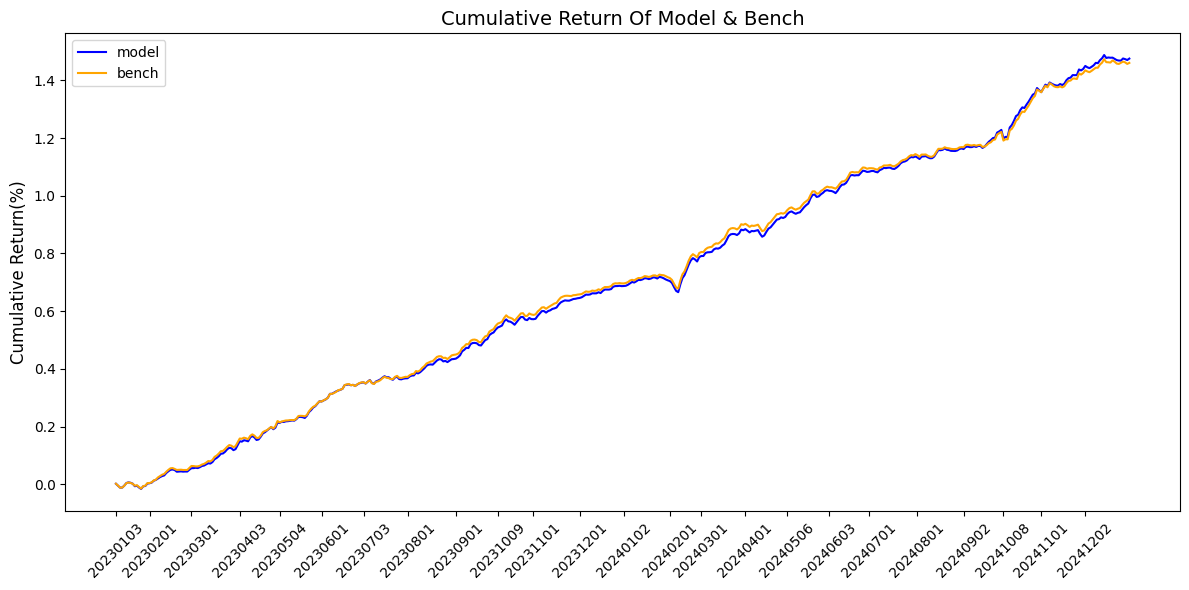

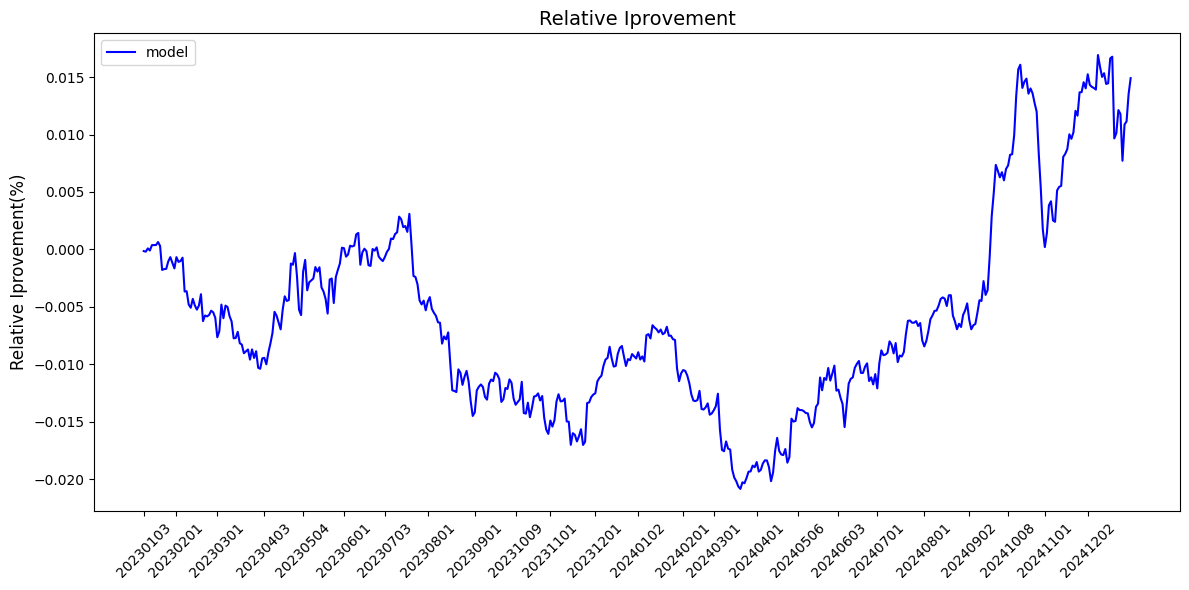

In [4]:
# 模型路径与结果路径
root_path = rf'/home/user96/20250909_MLP'
model_test_path = rf'{root_path}/model_test/nn--fac20250212_DE_first--label1--dropout0.2'
model_res_path = rf'{root_path}/model_res'
for path in [model_res_path]:
    os.makedirs(path, exist_ok=True)

# 收集模型训练结果
score1 = concat_model_4fold(test_path=model_test_path, res_path=model_res_path) 

# 单模型效果评估
print("---单一模型评估---")
score1_metrics = get_metrics(score1, params.ret_data, params.liquid_data, start='20230101', end='20241231', money=1.5e9, print_quarterly=True)
print_metrics(score1_metrics)
print("---该模型与现有集成模型的相关性---")
corr_with_bench = score1.reindex(columns=bench_all.columns, index=bench_all.index).corrwith(bench_all, axis=1)
print(f"{corr_with_bench.mean():.4f}")


print("---模型集成评估---")
bench_new = ensemble_scores(bench1, bench2, bench3, bench4, score1)
print(f'加入当前模型后的多样性熵：{de_series.mean()}')
print('当前模型与现有子模型之间的相关性：')
print(bench_new.groupby('date').corr().unstack().mean().unstack())
print("---与现有子模型集成效果---")
bench_new_metrics = get_metrics(bench_new.mean(axis=1).unstack(), params.ret_data, params.liquid_data, start='20230101', end='20241231', money=1.5e9, print_quarterly=True)
print_metrics(bench_new_metrics, bench_all_metrics)
plot_model(bench_new.mean(axis=1).unstack(), bench_all, params.ret_data, params.liquid_data, start='20230101', end='20241231', money=1.5e9)